# Car Price Prediction: Linear, Ridge and Lasso Regression
Predict a continuous target (`price`) using the [HellBuoy Kaggle dataset](https://www.kaggle.com/datasets/hellbuoy/car-price-prediction).

**Assignment:** a train/test split, three regression models, coefficient comparison, MAE / MSE / RMSE / R², and a 2–3 sentence conclusion. **Due:** November 1, 2026.

## tl;dr
**Linear Regression wins this held-out test split** (RMSE **2,669.93**, R² **0.9097**), but **Ridge is the preferred generalization candidate from training-only cross-validation** (CV RMSE **2,461.86**, versus **2,887.98** for Linear Regression). Ridge shrinks the coefficient norm; Lasso sets **15 of 63 coefficients to zero**. The disagreement between CV and 41 test cars makes the generalization ranking uncertain.

The notebook includes all four test metrics, the same train/test split for all three models, training-only alpha selection, full coefficient exports and a three-sentence conclusion.

## Context & Methods

- **Target:** `price`, in the dataset's original price units. No currency conversion or inflation adjustment is applied.
- **Split:** 80% training, 20% test; `random_state=42`. RMSE is the preselected model-selection criterion.
- **Fair comparison:** identical predictors, preprocessing and folds. Numeric variables are standardized, categories are one-hot encoded with a dropped reference category. Imputation, scaling and encoding are fitted within each training fold through a pipeline.
- **Selection:** choose each regularized model's alpha using training-only cross-validation; compare the three model families by the same CV RMSE. Evaluate the frozen fitted models once on the test set. Tuning CV results are descriptive and may be optimistic; they are not nested-CV estimates.
- **Linear Regression:** minimizes the sum of squared residuals. **Ridge:** adds an L2 penalty, `alpha * sum(coef²)`. **Lasso:** uses `sum(residual²)/(2*n) + alpha * sum(abs(coef))`; it can set coefficients exactly to zero. Alpha values are not numerically comparable between Ridge and Lasso because their objectives are scaled differently.

### Key Assumptions
Rows are independent cars drawn from a similar population; this random split does not establish performance on future market prices or unseen brands. Keep valid high-price cars rather than delete outliers based on the target. Drop the row identifier and replace the high-cardinality full car name with a normalized brand; all brand corrections are fixed spelling rules and use no price information.

**Metric definitions:** MAE = mean absolute error; MSE = mean squared error; RMSE = square root of MSE; R² = 1 − residual sum of squares / test total sum of squares. Lower MAE/MSE/RMSE and higher R² are better. MAE/RMSE have price units; MSE has squared price units; R² is unitless and can be negative.

### 1. Setup
Use Python 3.11+ with the packages in `requirements.txt` (tested with Python 3.14). Kaggle normally includes these packages. The notebook first uses an attached Kaggle dataset or a local CSV; otherwise it downloads the source archive, which requires internet. The CSV hash is checked so results cannot silently switch to a different dataset version.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
import hashlib
import json
import platform
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# A failed convergence check should be repaired, not hidden.
warnings.filterwarnings('error', category=ConvergenceWarning)
# Unseen validation categories are intentionally encoded as the reference level.
warnings.filterwarnings('ignore', message='Found unknown categories.*', category=UserWarning)
SEED = 42
SOURCE_URL = 'https://www.kaggle.com/datasets/hellbuoy/car-price-prediction'
DOWNLOAD_URL = 'https://www.kaggle.com/api/v1/datasets/download/hellbuoy/car-price-prediction'
EXPECTED_SHA256 = '2c78d99359a34cb6c64a97f276c1b6ea0532197b9b950b4521f65c0d9efcbc2b'
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)
COLORS = {'Linear Regression': '#285A8E', 'Ridge': '#A65C12', 'Lasso': '#7C488A'}
plt.rcParams.update({'figure.dpi': 125, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'NumPy {np.__version__} | scikit-learn {sklearn.__version__}')

Python 3.14.0 | pandas 3.0.0 | NumPy 2.4.2 | scikit-learn 1.8.0


## Data
### 2. Load and validate the source
The original archive contains `CarPrice_Assignment.csv` and a data dictionary. The source reports an unspecified/unknown dataset license; the repository supplies code and derived results and links to the original dataset rather than republishing its CSV.

In [2]:
candidates = [Path('CarPrice_Assignment.csv'), Path('data/CarPrice_Assignment.csv'),
              Path('../work/data/CarPrice_Assignment.csv')]
if Path('/kaggle/input').exists():
    candidates += sorted(Path('/kaggle/input').rglob('CarPrice_Assignment.csv'))
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is not None:
    raw_csv = data_path.read_bytes()
    loaded_from = str(data_path)
else:
    with urlopen(DOWNLOAD_URL, timeout=60) as response:
        archive = zipfile.ZipFile(BytesIO(response.read()))
    raw_csv = archive.read('CarPrice_Assignment.csv')
    loaded_from = DOWNLOAD_URL
actual_sha256 = hashlib.sha256(raw_csv).hexdigest()
assert actual_sha256 == EXPECTED_SHA256, 'Dataset changed: review the source before rerunning.'
df = pd.read_csv(BytesIO(raw_csv))
assert df.shape == (205, 26)
assert df['car_ID'].is_unique and df['price'].notna().all()
assert np.isfinite(df.select_dtypes(include='number').to_numpy()).all()
assert (df['price'] > 0).all()
quality = pd.DataFrame({'Check': ['Rows', 'Columns', 'Missing cells', 'Exact duplicate rows'],
                        'Value': [len(df), df.shape[1], int(df.isna().sum().sum()),
                                  int(df.duplicated().sum())]})
display(quality)
display(df[['CarName', 'enginesize', 'horsepower', 'curbweight', 'price']].head())
print('Source:', SOURCE_URL)
print('CSV SHA-256:', actual_sha256)

,Check,Value
0,Rows,205
1,Columns,26
2,Missing cells,0
3,Exact duplicate rows,0


,CarName,enginesize,horsepower,curbweight,price
0,alfa-romero giulia,130,111,2548,13495.0
1,alfa-romero stelvio,130,111,2548,16500.0
2,alfa-romero Quadrifoglio,152,154,2823,16500.0
3,audi 100 ls,109,102,2337,13950.0
4,audi 100ls,136,115,2824,17450.0


Source: https://www.kaggle.com/datasets/hellbuoy/car-price-prediction
CSV SHA-256: 2c78d99359a34cb6c64a97f276c1b6ea0532197b9b950b4521f65c0d9efcbc2b


### 3. Define predictors and freeze the test split
Brand spellings are normalized (`maxda` → `mazda`, `porcshce` → `porsche`, `toyouta` → `toyota`, and Volkswagen aliases). Full model names and `car_ID` are excluded. No data-driven feature selection or target-based capping is performed.

In [3]:
X = df.drop(columns=['price', 'car_ID', 'CarName']).copy()
X['brand'] = (df['CarName'].str.lower().str.strip().str.split().str[0]
              .replace({'maxda': 'mazda', 'porcshce': 'porsche', 'toyouta': 'toyota',
                        'vokswagen': 'volkswagen', 'vw': 'volkswagen'}))
y = df['price'].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
numeric_columns = X_train.select_dtypes(include='number').columns.tolist()
categorical_columns = [c for c in X_train.columns if c not in numeric_columns]
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(df)
print(f'Training: {len(X_train)} cars | Test: {len(X_test)} cars')
print(f'Predictors: {len(numeric_columns)} numeric + {len(categorical_columns)} categorical')

Training: 164 cars | Test: 41 cars
Predictors: 14 numeric + 10 categorical


### 4. Explore training data only
These two views show price spread and a prominent predictor relationship without consulting held-out prices. They describe association, not causal effects.

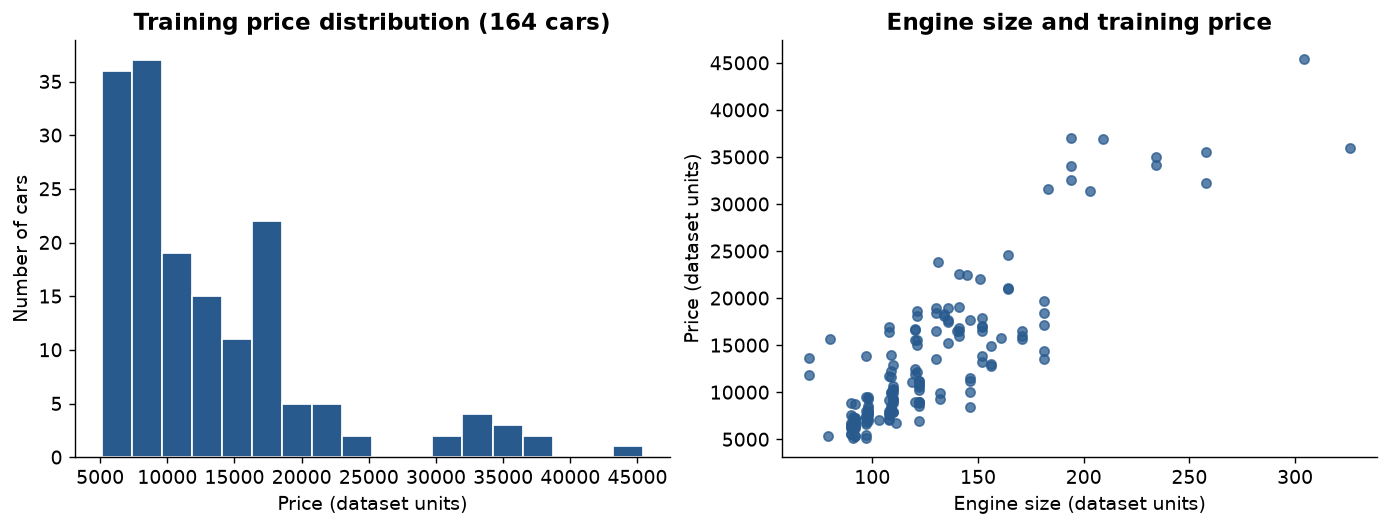

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), layout='constrained')
axes[0].hist(y_train, bins=18, color=COLORS['Linear Regression'], edgecolor='white')
axes[0].set(title='Training price distribution (164 cars)', xlabel='Price (dataset units)', ylabel='Number of cars')
axes[1].scatter(X_train['enginesize'], y_train, color=COLORS['Linear Regression'], alpha=.75, s=28)
axes[1].set(title='Engine size and training price', xlabel='Engine size (dataset units)', ylabel='Price (dataset units)')
fig.savefig(RESULTS_DIR / 'training_data.png', bbox_inches='tight')
plt.show()

## Results
### 5. Tune all models using training-only cross-validation
Use the same five shuffled folds for all models. Pipelines prevent preprocessing leakage. `GridSearchCV` refits each winning configuration on all 164 training cars; its test set remains unused. The alpha grids are fixed before seeing test results.

In [5]:
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),
                             ('scaler', StandardScaler())])
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                 ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore',
                                                           sparse_output=False))])
preprocessor = ColumnTransformer([('numeric', numeric_pipeline, numeric_columns),
                                  ('categorical', categorical_pipeline, categorical_columns)])
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
specifications = {
    'Linear Regression': (LinearRegression(), {}),
    'Ridge': (Ridge(), {'model__alpha': np.logspace(-3, 4, 29)}),
    'Lasso': (Lasso(max_iter=100000, tol=1e-5), {'model__alpha': np.logspace(-2, 3, 31)})
}
searches, models, cv_rows = {}, {}, []
for name, (estimator, grid) in specifications.items():
    pipeline = Pipeline([('preprocess', preprocessor), ('model', estimator)])
    search = GridSearchCV(pipeline, grid, scoring='neg_root_mean_squared_error',
                          cv=cv, n_jobs=1, error_score='raise', return_train_score=True)
    search.fit(X_train, y_train)
    searches[name], models[name] = search, search.best_estimator_
    idx = search.best_index_
    cv_rows.append({'Model': name, 'Selected alpha': search.best_params_.get('model__alpha', np.nan),
                    'CV RMSE': -search.best_score_,
                    'CV fold SD': search.cv_results_['std_test_score'][idx]})
cv_comparison = pd.DataFrame(cv_rows).set_index('Model')
cv_selected_model = cv_comparison['CV RMSE'].idxmin()
display(cv_comparison.round(3))
print('Model selected before test evaluation:', cv_selected_model)
print('CV fold SD describes fold variation, not a confidence interval.')
for name in ['Ridge', 'Lasso']:
    selected_alpha = searches[name].best_params_['model__alpha']
    alpha_grid = specifications[name][1]['model__alpha']
    assert alpha_grid.min() < selected_alpha < alpha_grid.max(), 'Review alpha search boundary.'

,Selected alpha,CV RMSE,CV fold SD
Model,,,
Linear Regression,NaN,2887.979,556.641
Ridge,0.316,2461.855,256.794
Lasso,6.813,2497.656,260.234


Model selected before test evaluation: Ridge
CV fold SD describes fold variation, not a confidence interval.


### 6. Evaluate the three frozen models
MAE and RMSE are in price units; MSE is in squared price units. Metrics below are calculated from the same 41 test cars. Training RMSE is included separately to make overfitting visible. Predictions are scored directly, without clipping negative values to zero.

In [6]:
predictions, metric_rows, fit_rows = {}, [], []
for name, model in models.items():
    prediction = model.predict(X_test)
    predictions[name] = prediction
    mse = mean_squared_error(y_test, prediction)
    metric_rows.append({'Model': name, 'MAE': mean_absolute_error(y_test, prediction),
                        'MSE': mse, 'RMSE': np.sqrt(mse), 'R²': r2_score(y_test, prediction)})
    fit_rows.append({'Model': name,
                     'Train RMSE': np.sqrt(mean_squared_error(y_train, model.predict(X_train))),
                     'Test RMSE': np.sqrt(mse)})
comparison = pd.DataFrame(metric_rows).set_index('Model')
fit_comparison = pd.DataFrame(fit_rows).set_index('Model')
display(comparison.style.format({'MAE': '{:,.2f}', 'MSE': '{:,.2f}', 'RMSE': '{:,.2f}', 'R²': '{:.4f}'}))
display(fit_comparison.round(2))
test_winner = comparison['RMSE'].idxmin()
print('Lowest observed test RMSE:', test_winner)
print(f'Mean-only baseline test RMSE: {np.sqrt(mean_squared_error(y_test, np.repeat(y_train.mean(), len(y_test)))):,.2f}')

,MAE,MSE,RMSE,R²
Model,,,,
Linear Regression,"1,763.57","7,128,546.78","2,669.93",0.9097
Ridge,"1,860.67","7,515,138.98","2,741.38",0.9048
Lasso,"1,962.95","8,357,517.65","2,890.94",0.8941


,Train RMSE,Test RMSE
Model,,
Linear Regression,1228.25,2669.93
Ridge,1284.38,2741.38
Lasso,1334.38,2890.94


Lowest observed test RMSE: Linear Regression
Mean-only baseline test RMSE: 8,889.04


### 7. Compare test errors and predictions
Bar lengths start at zero; numerical labels retain exact comparison detail. The diagonal is perfect prediction and both scatter axes use the same price scale.

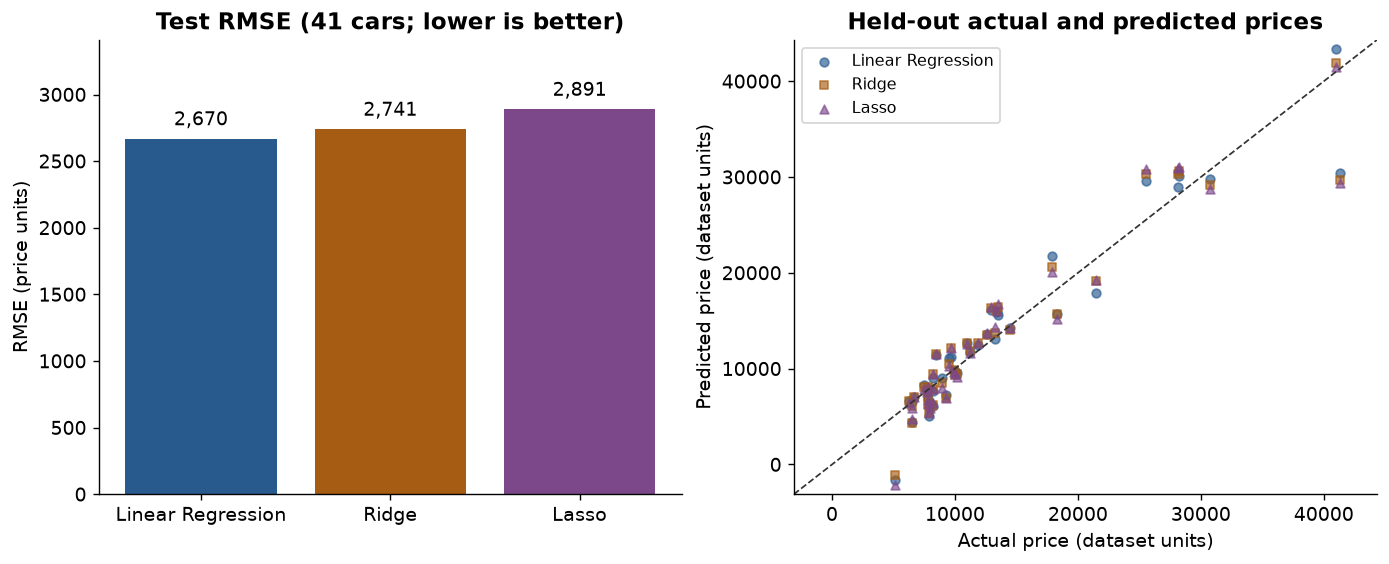

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout='constrained')
names = list(models)
bars = axes[0].bar(names, comparison.loc[names, 'RMSE'], color=[COLORS[n] for n in names])
axes[0].bar_label(bars, labels=[f'{v:,.0f}' for v in comparison.loc[names, 'RMSE']], padding=5)
axes[0].set(title='Test RMSE (41 cars; lower is better)', ylabel='RMSE (price units)', ylim=(0, comparison['RMSE'].max()*1.18))
markers = ['o', 's', '^']
for name, marker in zip(names, markers):
    axes[1].scatter(y_test, predictions[name], label=name, color=COLORS[name], marker=marker, alpha=.65, s=25)
bound_low = min(y_test.min(), min(p.min() for p in predictions.values())) - 1000
bound_high = max(y_test.max(), max(p.max() for p in predictions.values())) + 1000
axes[1].plot([bound_low, bound_high], [bound_low, bound_high], '--', color='#333333', linewidth=1)
axes[1].set(xlim=(bound_low,bound_high), ylim=(bound_low,bound_high), title='Held-out actual and predicted prices',
            xlabel='Actual price (dataset units)', ylabel='Predicted price (dataset units)')
axes[1].legend(fontsize=9, loc='upper left')
fig.savefig(RESULTS_DIR / 'test_comparison.png', bbox_inches='tight')
plt.show()

### 8. Compare coefficients on the same feature basis
Numeric coefficients represent a one-training-standard-deviation increase, holding other inputs fixed. Dummy coefficients represent a category change from its omitted reference level; they are not standardized, so do not use their magnitudes to rank all features together. Compare each feature across models; signs and sizes are conditional associations, not causal effects.

Ridge generally reduces total coefficient magnitude rather than forcing zeros; individual coefficients can increase or change sign when predictors are correlated. Lasso uses exact zeros for a sparser model. The full coefficient table is exported as `coefficients.csv`; the displayed subset contains all numeric predictors.

In [8]:
feature_names = models['Linear Regression'].named_steps['preprocess'].get_feature_names_out()
coefficients = pd.DataFrame({name: model.named_steps['model'].coef_ for name, model in models.items()},
                             index=feature_names)
coefficients.index.name = 'Feature'
assert all(np.array_equal(feature_names, m.named_steps['preprocess'].get_feature_names_out()) for m in models.values())
coefficient_summary = pd.DataFrame({
    name: {'L1 norm (sum absolute coefficients)': np.abs(values).sum(),
           'L2 norm': np.linalg.norm(values),
           'Zero coefficients (abs < 1e-8)': int((np.abs(values) < 1e-8).sum()),
           'Total coefficients': len(values),
           'Intercept': models[name].named_steps['model'].intercept_}
    for name, values in coefficients.items()
}).T
display(coefficient_summary.round(3))
display(coefficients.loc[[f'numeric__{c}' for c in numeric_columns]].round(2))
references = models['Linear Regression'].named_steps['preprocess'].named_transformers_['categorical'].named_steps['encoder']
display(pd.DataFrame({'Categorical predictor': categorical_columns,
                      'Reference category': [cats[int(idx)] for cats, idx in zip(references.categories_, references.drop_idx_)]}))

,L1 norm (sum absolute coefficients),L2 norm,Zero coefficients (abs < 1e-8),Total coefficients,Intercept
Linear Regression,150841.109,23191.691,0.0,63.0,19170.058
Ridge,104018.289,17031.013,0.0,63.0,16726.201
Lasso,81278.303,18036.434,15.0,63.0,14526.939


,Linear Regression,Ridge,Lasso
Feature,,,
numeric__symboling,-282.25,-81.61,-29.05
numeric__wheelbase,1481.70,1077.67,910.61
numeric__carlength,-1915.07,-1407.07,-1182.81
numeric__carwidth,1204.43,1211.55,1200.37
numeric__carheight,-576.74,-269.88,-246.14
numeric__curbweight,3367.44,2830.54,2983.37
numeric__enginesize,3873.92,3627.81,3349.94
numeric__boreratio,-1118.00,-942.13,-914.29
numeric__stroke,-247.78,-359.08,-325.49


,Categorical predictor,Reference category
0,fueltype,diesel
1,aspiration,std
2,doornumber,four
3,carbody,convertible
4,drivewheel,4wd
5,enginelocation,front
6,enginetype,dohc
7,cylindernumber,eight
8,fuelsystem,1bbl
9,brand,alfa-romero


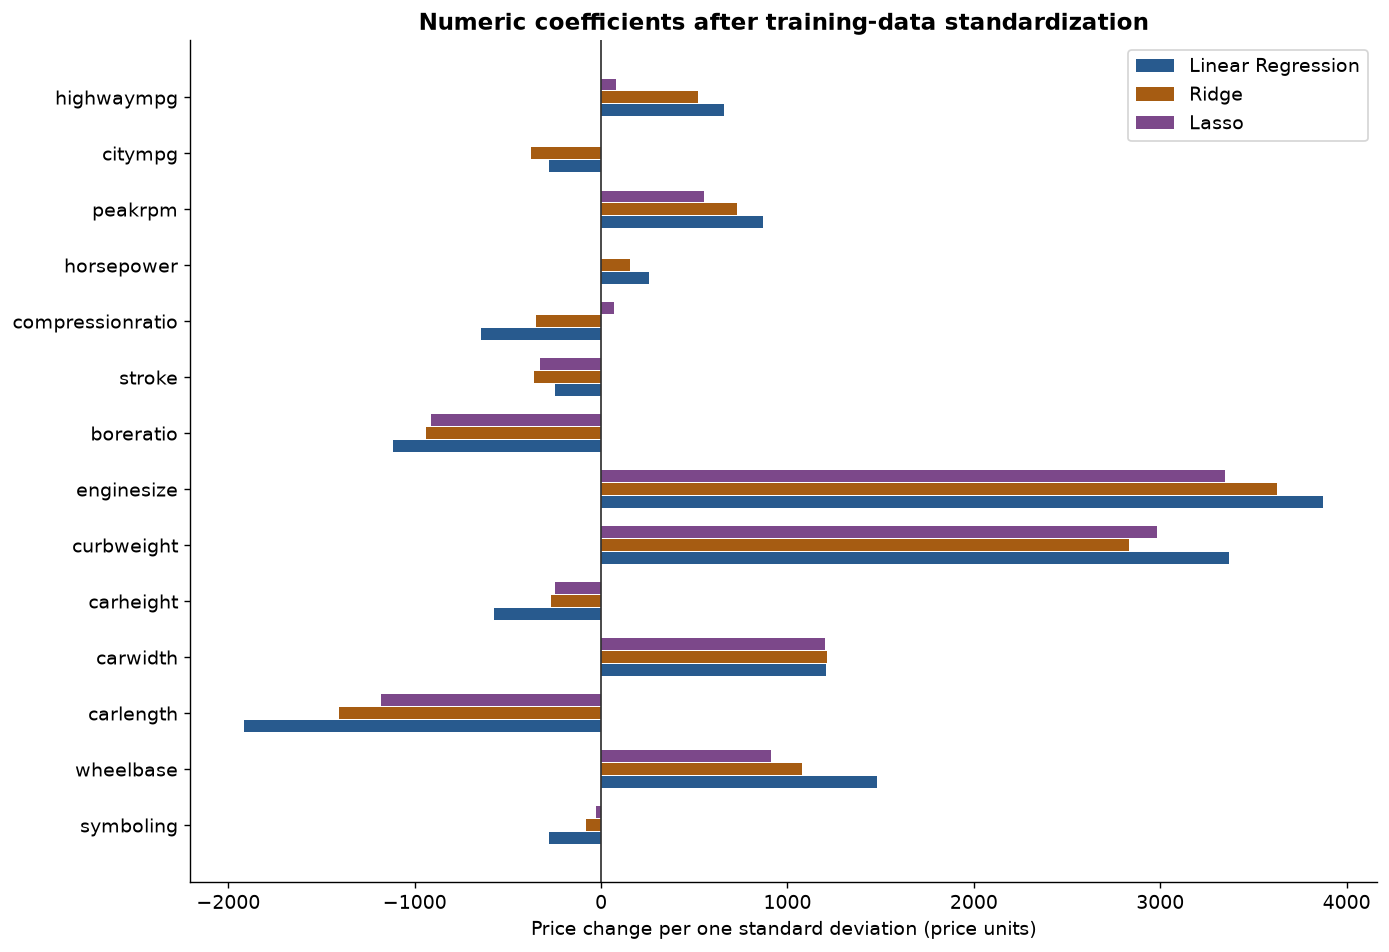

In [9]:
numeric_features = [f'numeric__{c}' for c in numeric_columns]
plot_data = coefficients.loc[numeric_features].copy()
plot_data.index = [s.removeprefix('numeric__') for s in plot_data.index]
fig, ax = plt.subplots(figsize=(11, 7.5), layout='constrained')
positions = np.arange(len(plot_data))
for offset, name in zip([-.23, 0, .23], names):
    ax.barh(positions + offset, plot_data[name], height=.21, label=name, color=COLORS[name])
ax.set_yticks(positions, plot_data.index)
ax.axvline(0, color='#333333', linewidth=1)
ax.set(title='Numeric coefficients after training-data standardization',
       xlabel='Price change per one standard deviation (price units)')
ax.legend(loc='best')
fig.savefig(RESULTS_DIR / 'coefficient_comparison.png', bbox_inches='tight')
plt.show()

## Takeaways
### 9. Three-sentence conclusion
The text is calculated from the executed outputs, so the recommended model and coefficient counts remain consistent with the tables.

In [10]:
best = comparison.loc[test_winner]
ridge_norm = coefficient_summary.loc['Ridge', 'L2 norm']
linear_norm = coefficient_summary.loc['Linear Regression', 'L2 norm']
lasso_zeros = int(coefficient_summary.loc['Lasso', 'Zero coefficients (abs < 1e-8)'])
total_features = len(coefficients)
conclusion = (
    f'{cv_selected_model} is the preferred generalization candidate from training-only '
    f'cross-validation (RMSE {cv_comparison.loc[cv_selected_model, "CV RMSE"]:,.2f} '
    f'versus {cv_comparison.loc["Linear Regression", "CV RMSE"]:,.2f} for Linear Regression), '
    f'although {test_winner} wins this 41-car test split '
    f'(RMSE {best["RMSE"]:,.2f}, R² = {best["R²"]:.4f}). '
    f'Regularization controls coefficient size: Ridge has L2 coefficient norm {ridge_norm:,.1f} '
    f'versus {linear_norm:,.1f} for unregularized regression, while Lasso sets '
    f'{lasso_zeros} of {total_features} coefficients to zero. '
    'Regularization reduces model flexibility and sensitivity to correlated predictors, '
    'but the disagreement between cross-validation and the small test set means its '
    'generalization advantage remains uncertain.'
)
display(Markdown(conclusion))

Ridge is the preferred generalization candidate from training-only cross-validation (RMSE 2,461.86 versus 2,887.98 for Linear Regression), although Linear Regression wins this 41-car test split (RMSE 2,669.93, R² = 0.9097). Regularization controls coefficient size: Ridge has L2 coefficient norm 17,031.0 versus 23,191.7 for unregularized regression, while Lasso sets 15 of 63 coefficients to zero. Regularization reduces model flexibility and sensitivity to correlated predictors, but the disagreement between cross-validation and the small test set means its generalization advantage remains uncertain.

### 10. Save tables and verify calculations
Recompute all four requested metrics directly from residuals, confirm the saved split and complete coefficient comparison, and save machine-readable results. No test results feed back into training or alpha selection.

In [11]:
for name, prediction in predictions.items():
    residuals = y_test.to_numpy() - prediction
    expected = [np.abs(residuals).mean(), (residuals**2).mean(),
                np.sqrt((residuals**2).mean()),
                1 - (residuals**2).sum() / ((y_test-y_test.mean())**2).sum()]
    np.testing.assert_allclose(comparison.loc[name].to_numpy(dtype=float), expected, rtol=1e-10)
assert comparison.shape == (3, 4) and np.isfinite(comparison.to_numpy()).all()
assert int(coefficient_summary.loc['Lasso', 'Zero coefficients (abs < 1e-8)']) >= 0
comparison.to_csv(RESULTS_DIR / 'model_comparison.csv')
coefficients.to_csv(RESULTS_DIR / 'coefficients.csv')
coefficient_summary.to_csv(RESULTS_DIR / 'coefficient_summary.csv')
cv_comparison.to_csv(RESULTS_DIR / 'cross_validation.csv')
fit_comparison.to_csv(RESULTS_DIR / 'train_test_rmse.csv')
pd.DataFrame({'row_index': df.index, 'car_ID': df['car_ID'],
              'split': np.where(df.index.isin(X_train.index), 'train', 'test')}).to_csv(RESULTS_DIR / 'split_manifest.csv', index=False)
prediction_table = pd.DataFrame({'car_ID': df.loc[y_test.index, 'car_ID'], 'actual_price': y_test,
                                 **{name: pred for name, pred in predictions.items()}})
prediction_table.to_csv(RESULTS_DIR / 'test_predictions.csv', index=False)
(RESULTS_DIR / 'CONCLUSION.md').write_text(conclusion + '\n', encoding='utf-8')
provenance = {'dataset': 'hellbuoy/car-price-prediction', 'source_url': SOURCE_URL,
              'csv_sha256': actual_sha256, 'rows': len(df), 'test_rows': len(y_test),
              'seed': SEED, 'test_fraction': .20, 'cv_folds': 5, 'selection_metric': 'RMSE',
              'cv_selected_model': cv_selected_model, 'test_rmse_winner': test_winner,
              'python': platform.python_version(), 'pandas': pd.__version__,
              'numpy': np.__version__, 'scikit_learn': sklearn.__version__}
(RESULTS_DIR / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
print('Verified all four metrics independently for all three models. Results saved in:', RESULTS_DIR)

Verified all four metrics independently for all three models. Results saved in: results


### References
- [Dataset and source files — HellBuoy, Kaggle](https://www.kaggle.com/datasets/hellbuoy/car-price-prediction)
- [scikit-learn: Linear, Ridge and Lasso objectives](https://scikit-learn.org/stable/modules/linear_model.html)
- [scikit-learn: GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

**Limits:** a small historical dataset and one random test split; no claim about current car valuations. Categories absent from a training fold map to the all-zero reference representation. Collinearity can make OLS coefficients non-unique; the solver returns a least-squares solution, so coefficient interpretation should focus on the regularization comparison rather than causal importance. These unconstrained linear models can predict negative prices; the prediction chart exposes this failure and the reported metrics include it.